In [16]:
import sys
from pathlib import Path

import data_loader as dl
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
import torch.backends.cudnn as cudnn
import numpy as np
import torchvision
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt
import time
import os
from PIL import Image
from tempfile import TemporaryDirectory

cudnn.benchmark = True
plt.ion()

In [17]:
#load pretrained resNet18 model
model = models.resnet18()

In [18]:
num_classes = 28
model.fc = torch.nn.Linear(model.fc.in_features, num_classes)

In [19]:
# Index images without loading them into memory, then split by class label.
from sklearn.model_selection import train_test_split

dataset = dl.build_dataset(size=64, transpose=True)
indices = np.arange(len(dataset))
train_val_indices, test_indices = train_test_split(
    indices,
    test_size=0.15,
    random_state=42,
    stratify=dataset.labels,
)

val_size_relative = 0.15 / (1.0 - 0.15)
train_indices, val_indices = train_test_split(
    train_val_indices,
    test_size=val_size_relative,
    random_state=42,
    stratify=dataset.labels[train_val_indices],
)

train_dataset = dataset.subset(train_indices)
val_dataset = dataset.subset(val_indices)
test_dataset = dataset.subset(test_indices)

print(f"Indexed images: {len(dataset)}")
print(f"Training samples: {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")
print(f"Test samples: {len(test_dataset)}")

Indexed images: 42000
Training samples: 29400
Validation samples: 6300
Test samples: 6300


In [20]:
# Define the loss function and optimizer
criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.fc.parameters(), lr=0.005)

In [21]:
# Inspect one lazy test batch without loading the full test set.
batch_images, batch_labels, _ = next(test_dataset.iter_batches(batch_size=32, shuffle=False))
print(f"Image batch shape: {batch_images.shape}")
print(f"Label index shape: {np.argmax(batch_labels, axis=1).shape}")

Image batch shape: (32, 3, 64, 64)
Label index shape: (32,)


Training the model

In [22]:
def train_model(model, criterion, optimizer, scheduler, num_epochs=25):
    since = time.time()
    history = {
        "epoch": [],
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": [],
    }

    # Create a temporary directory to save training checkpoints
    with TemporaryDirectory() as tempdir:
        best_model_params_path = os.path.join(tempdir, 'best_model_params.pt')
        torch.save(model.state_dict(), best_model_params_path)
        best_acc = 0.0

        for epoch in range(num_epochs):
            print(f'Epoch {epoch}/{num_epochs - 1}')
            print('-' * 10)

            for phase in ['train', 'val']:
                loader = train_dataset if phase == 'train' else val_dataset
                model.train() if phase == 'train' else model.eval()
                running_loss = 0.0
                running_corrects = 0
                samples_seen = 0

                for image_batch, one_hot_labels, _ in loader.iter_batches(
                    batch_size=32,
                    shuffle=(phase == 'train'),
                ):
                    inputs = torch.from_numpy(image_batch)
                    labels = torch.from_numpy(one_hot_labels).argmax(dim=1).long()
                    optimizer.zero_grad()

                    with torch.set_grad_enabled(phase == 'train'):
                        outputs = model(inputs)
                        _, preds = torch.max(outputs, 1)
                        loss = criterion(outputs, labels)

                        if phase == 'train':
                            loss.backward()
                            optimizer.step()

                    batch_count = inputs.size(0)
                    running_loss += loss.item() * batch_count
                    running_corrects += int(torch.sum(preds == labels).item())
                    samples_seen += batch_count

                if samples_seen == 0:
                    raise ValueError(f'No readable images available in the {phase} dataset')
                if phase == 'train':
                    scheduler.step()

                epoch_loss = running_loss / samples_seen
                epoch_acc = running_corrects / samples_seen
                history[f'{phase}_loss'].append(epoch_loss)
                history[f'{phase}_accuracy'].append(epoch_acc)
                print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

                if phase == 'val':
                    history['epoch'].append(epoch + 1)
                    if epoch_acc > best_acc:
                        best_acc = epoch_acc
                        torch.save(model.state_dict(), best_model_params_path)

            print()

        time_elapsed = time.time() - since
        print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
        print(f'Best val Acc: {best_acc:4f}')
        model.load_state_dict(torch.load(best_model_params_path, weights_only=True))
    return model, history

Fine tune Model

In [23]:
model_ft = models.resnet18(weights="IMAGENET1K_V1")
num_ftrs = model_ft.fc.in_features
model_ft.fc = nn.Linear(num_ftrs, 28)

criterion = nn.CrossEntropyLoss()
optimizer_ft = optim.SGD(model_ft.parameters(), lr=0.001, momentum=0.9)
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)

In [25]:
# Train and evaluate, retaining metrics for the performance plots.
model_ft, training_history = train_model(
    model_ft,
    criterion,
    optimizer_ft,
    exp_lr_scheduler,
    num_epochs = 20,
)

Epoch 0/19
----------
train Loss: 0.5916 Acc: 0.8407
val Loss: 0.0469 Acc: 0.9905

Epoch 1/19
----------
train Loss: 0.0457 Acc: 0.9907
val Loss: 0.0312 Acc: 0.9921

Epoch 2/19
----------
train Loss: 0.0185 Acc: 0.9964
val Loss: 0.0099 Acc: 0.9976

Epoch 3/19
----------
train Loss: 0.0103 Acc: 0.9987
val Loss: 0.0068 Acc: 0.9979

Epoch 4/19
----------
train Loss: 0.0054 Acc: 0.9995
val Loss: 0.0057 Acc: 0.9981

Epoch 5/19
----------
train Loss: 0.0045 Acc: 0.9996
val Loss: 0.0069 Acc: 0.9978

Epoch 6/19
----------
train Loss: 0.0039 Acc: 0.9995
val Loss: 0.0049 Acc: 0.9989

Epoch 7/19
----------
train Loss: 0.0023 Acc: 1.0000
val Loss: 0.0053 Acc: 0.9989

Epoch 8/19
----------
train Loss: 0.0024 Acc: 0.9998
val Loss: 0.0051 Acc: 0.9987

Epoch 9/19
----------
train Loss: 0.0022 Acc: 0.9999
val Loss: 0.0054 Acc: 0.9984

Epoch 10/19
----------
train Loss: 0.0022 Acc: 0.9999
val Loss: 0.0053 Acc: 0.9986

Epoch 11/19
----------
train Loss: 0.0021 Acc: 0.9999
val Loss: 0.0047 Acc: 0.9986

Ep

TypeError: unsupported operand type(s) for /: 'str' and 'str'

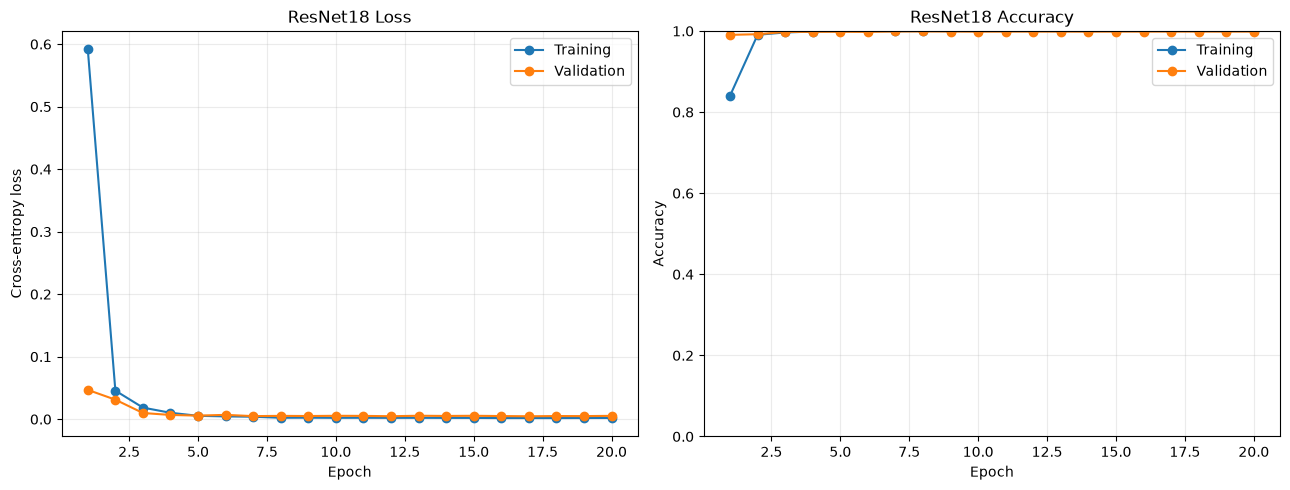

In [ ]:
epochs = training_history["epoch"]
fig, axes = plt.subplots(1, 2, figsize = (13, 5))

axes[0].plot(epochs, training_history["train_loss"], marker = "o", label = "Training")
axes[0].plot(epochs, training_history["val_loss"], marker = "o", label = "Validation")
axes[0].set_title("ResNet18 Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].grid(alpha = 0.25)
axes[0].legend()

axes[1].plot(epochs, training_history["train_accuracy"], marker = "o", label = "Training")
axes[1].plot(epochs, training_history["val_accuracy"], marker = "o", label = "Validation")
axes[1].set_title("ResNet18 Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0.0, 1.0)
axes[1].grid(alpha = 0.25)
axes[1].legend()

fig.tight_layout()
plot_path = "models/resnet_training_performance.png"
fig.savefig(plot_path, dpi = 150, bbox_inches = "tight")
print(f"Saved performance plots: {plot_path}")
plt.show()

In [ ]:
resnet_checkpoint = source_root / "models" / "resnet_sign_language.pth"
torch.save(model_ft.state_dict(), resnet_checkpoint)
print(f"Saved trained ResNet checkpoint: {resnet_checkpoint}")

In [ ]:
model = models.resnet18(weights=None)

model.fc = nn.Linear(
    model.fc.in_features,
    28
)

model.load_state_dict(
    torch.load(
        "resnet_sign_language.pth",
        weights_only=True
    )
)

In [ ]:
# Use the same normalized BGR, CHW inputs as the custom network.
prediction_dataset = dl.build_dataset(size=64, transpose=True)
sample_images, _, _ = next(prediction_dataset.iter_batches(batch_size=1, shuffle=False))
image = torch.from_numpy(sample_images)
image.shape

In [ ]:
with torch.no_grad():
    outputs = model(image)

_, predicted = torch.max(outputs, 1)
print(predicted)

In [ ]:
class_names = [
    'A', 'B', 'C', 'D', 'E', 'F', 'G',
    'H', 'I', 'J', 'K', 'L', 'M', 'N',
    'O', 'P', 'Q', 'R', 'S', 'T', 'U',
    'V', 'W', 'X', 'Y', 'Z', 'DEL', 'SPACE'
]

predicted_class = class_names[predicted.item()]

print(predicted_class)

In [ ]:
from sklearn.model_selection import train_test_split

hand_detection_root = source_root / "hand_detection"
if str(hand_detection_root) not in sys.path:
    sys.path.insert(0, str(hand_detection_root))

import resnet_inference
from resnet_inference import ResNetSignLanguageClassifier

resnet_checkpoint = source_root / "models" / "resnet_sign_language.pth"
evaluation_dataset = dl.build_dataset(size=64, transpose=True)

_, test_indices = train_test_split(
    np.arange(len(evaluation_dataset)),
    test_size=0.15,
    random_state=42,
    stratify=evaluation_dataset.labels,
)
test_dataset = evaluation_dataset.subset(test_indices)

resnet_classifier = ResNetSignLanguageClassifier(
    checkpoint_path=resnet_checkpoint,
    device="cuda" if torch.cuda.is_available() else "cpu",
)

MAX_EVALUATION_SAMPLES = 512
resnet_metrics = resnet_classifier.evaluate_dataset(
    test_dataset,
    batch_size=32,
    max_samples=MAX_EVALUATION_SAMPLES,
)
print(f"Checkpoint: {resnet_checkpoint}")
print(f"Device: {resnet_classifier.device}")
print(f"Input shape: (3, 64, 64)")
print(f"Evaluated samples: {resnet_metrics['samples']}")
print(f"Test loss: {resnet_metrics['loss']:.4f}")
print(f"Test accuracy: {resnet_metrics['accuracy']:.4f}")

sample_images, sample_labels, _ = next(test_dataset.iter_batches(batch_size=1, shuffle=False))
sample_bgr = (sample_images[0].transpose(1, 2, 0)[:, :, ::-1] * 255).clip(0, 255).astype(np.uint8)
expected_class = resnet_inference.CLASS_NAMES[int(np.argmax(sample_labels[0]))]
print(f"Expected sample class: {expected_class}")
print(f"Top-3 prediction: {resnet_classifier.predict_bgr(sample_bgr, top_k=3)}")